In [1]:
import os
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
import pandas as pd

import re
from pathlib import Path

In [2]:
# to postprocess data individually and compare them
dual_monopole_dir = "Data 260526/test_monopole_dual/"
near_dipole_dir = "Data 260526/test_dipole_near/"
far_dipole_dir = "Data 260526/test_dipole_far/"
far_dipole_dir_new = "Data 260526/test_dipole_far_new/"
mono_dir = 'Data 260526/test_monopole/'
test_mach = 'Data 260526/test_mach/'
error_test = "Data 260527/error_test/"
test_mach_new = 'Data 260527/test_mach/'

def fwh_data(dir, file):
    return pd.read_csv(f"{dir}{file}",
                    sep=r'\s+', 
                    header=None, 
                    names=['Time', 'P_obs', 'P_analytical'])

def updated_fwh_data(dir, file):
    return pd.read_csv(f'{dir}{file}',
                       sep=r'\s+',
                       skiprows=1,
                       names=['Time','P_obs'])

# make sure to keep data1 as reference or dual monopole data

def L2(data1, data2, col1, col2):
    if len(data1) != len(data2):
        t_fine = data1['Time'].values
        t_coarse = data2['Time'].values
        p_num_coarse = data2[col2].values
        p_num_interp = np.interp(t_fine, t_coarse, p_num_coarse)
        abs_error = np.linalg.norm(data1[col1].to_numpy() - p_num_interp)
    
    else:
        abs_error = np.linalg.norm(data1[col1].to_numpy() - data2[col2].to_numpy())

    return abs_error / (np.linalg.norm(data1[col1]) + 1e-15) # paper methodology
    # return (np.sum((data1[col] - data2[col]) ** 2) / np.sum((data1[col])**2)) # L2 norm

def plot_numerical(data1, data2, title=None):
    # comparing dual monopole and dipole numerical solutions
    error = L2(data1, data2 , "P_obs", "P_obs")
    scale = 1e5

    fig, ax = plt.subplots(figsize=(6,4))
    # ax.plot(data1['Time'], data1['P_analytical'], ls='-', c='black', label='Analytical')
    ax.plot(data1['Time'], data1['P_obs'] * scale, ls='-.', c='red', label='Dual Monopole')
    ax.plot(data2['Time'], data2['P_obs'] * scale , ls=':', c='blue', label='Dipole Derivation')

    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Pressure ($x10^{-5}$ Pa)")
    ax.grid()
    ax.set_title(title)
    ax.legend(title=f"Error: {error * 100:.2f}%", loc='upper right')
    plt.show()

def plot_analytical(data, title=None):
    # comparing analytical and numerical solutions
    error = L2(data, data, "P_analytical", "P_obs")
    scale = 1e5

    fig, ax = plt.subplots(figsize=(6,4))
    ax.plot(data['Time'], data['P_analytical'] * scale, ls='-', c='black', label='Analytical')
    ax.plot(data['Time'], data['P_obs'] * scale, ls=':', c='red', label='Numerical')

    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Pressure ($x10^{-5}$ Pa)")
    ax.set_title(title)
    ax.grid()
    ax.legend(title=f"Error: {error * 100:.2f}%", loc='upper right')
    plt.show()

def plot_mono(data1, data2, data3, analysis, title=None):
    data = [data1, data2, data3]
    error = []
    for i in data:
        error.append(L2(data1, i, 'P_analytical', 'P_obs'))

    if analysis == 'grid':
        labels = [f'40x40 Grid, Error: {error[0] * 100:.2f}%', f'15x15 Grid, Error: {error[1] * 100:.2f}%', f'5x5 Grid, Error: {error[2] * 100:.2f}%']
    elif analysis =='time':
        labels = [f'dt=0.005s, Error: {error[0] * 100:.2f}%', f'dt=0.025s, Error: {error[1] * 100:.2f}%', f'dt=0.125s, Error: {error[2] * 100:.2f}%']
   
    fig, ax = plt.subplots(figsize=(6,4))
    ax.plot(data1['Time'], data1['P_analytical'], ls='-', c='black', label='Analytical')
    ax.plot(data1['Time'], data1['P_obs'] , ls=':', c='red', label=labels[0])
    ax.plot(data2['Time'], data2['P_obs'] , ls=':', c='green', label=labels[1])
    ax.plot(data3['Time'], data3['P_obs'] , ls=':', c='blue', label=labels[2])

    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Pressure (Pa)")
    ax.set_title(title)
    ax.grid()
    ax.legend(loc='upper right')
    plt.show()

def plot_mach(data_ana, data1, data2, data3, analysis=None, title=None):
    num_data = [data1, data2, data3]
    error = []
    for i in num_data:
        error.append(L2(data_ana, i, "P_obs", "P_obs"))

    if analysis == 'grid':
        labels = [f'40x40 Grid, Error: {error[0] * 100:.2f}%', f'15x15 Grid, Error: {error[1] * 100:.2f}%', f'5x5 Grid, Error: {error[2] * 100:.2f}%']
    elif analysis =='time':
        labels = [f'dt=0.005s, Error: {error[0] * 100:.2f}%', f'dt=0.025s, Error: {error[1] * 100:.2f}%', f'dt=0.125s, Error: {error[2] * 100:.2f}%']
    elif analysis == 'radius':
        labels = [f'r=50m, Error: {error[0] * 100:.2f}%', f'r=100m, Error: {error[1] * 100:.2f}%', f'r=200m, Error: {error[2] * 100:.2f}%',]
    else:
        labels = [f'Error: {error[0] * 100:.2f}%', f'Error: {error[1] * 100:.2f}%', f'Error: {error[2] * 100:.2f}%']

    fig, ax = plt.subplots(figsize=(6,4))
    ax.plot(data_ana['Time'], data_ana['P_obs'], ls='-', c='black', label='Analytical')
    ax.plot(data1['Time'], data1['P_obs'], ls=':', c='red', label=labels[0])
    ax.plot(data2['Time'], data2['P_obs'], ls=':', c='green', label=labels[1])
    ax.plot(data3['Time'], data3['P_obs'], ls=':', c='blue', label=labels[2])


    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Pressure (Pa)")
    ax.set_title(title)
    ax.grid()
    ax.legend(loc='upper right')
    plt.show()

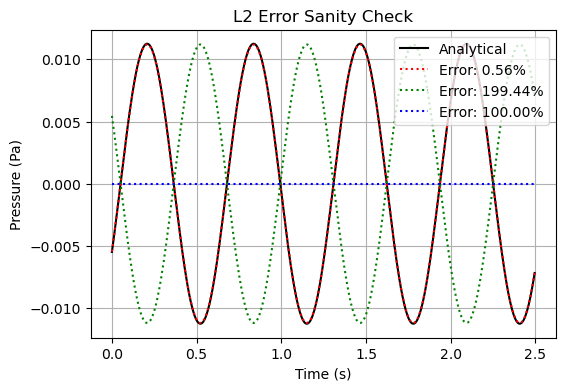

In [3]:
mono_ana = updated_fwh_data(error_test, 'mono_analytical.dat')
mono_pos = updated_fwh_data(error_test, 'mono_positive.dat')
mono_neg = updated_fwh_data(error_test, 'mono_negative.dat')
mono_zer = updated_fwh_data(error_test, 'mono_zero.dat')

plot_mach(mono_ana, mono_pos, mono_neg, mono_zer,None, 'L2 Error Sanity Check')

In [6]:
dual_near_valid = fwh_data(dual_monopole_dir, "dual_near_valid.dat")
dual_near_invalid = fwh_data(dual_monopole_dir, "dual_near_invalid.dat")
dual_far_valid = fwh_data(dual_monopole_dir, "dual_far_valid.dat")
dual_far_invalid = fwh_data(dual_monopole_dir, "dual_far_invalid.dat")

near_valid = fwh_data(near_dipole_dir, "dipole_near_valid.dat")
near_invalid = fwh_data(near_dipole_dir, "dipole_near_invalid.dat")
far_valid = fwh_data(far_dipole_dir, "dipole_far_valid.dat")
far_invalid = fwh_data(far_dipole_dir, "dipole_far_invalid.dat")

# far_new = fwh_data(far_dipole_dir_new, "FWH_pressure_new.dat")
# dual_new = fwh_data(dual_monopole_dir, "FWH_pressure_new.dat")

ss_coarse_fine = fwh_data(mono_dir, "ss_coarse_fine.dat")
ss_med_fine = fwh_data(mono_dir, "ss_med_fine.dat")
ss_fine_fine = fwh_data(mono_dir, "ss_fine_fine.dat")

ts_coarse_fine = fwh_data(mono_dir, "ts_coarse_fine.dat")
ts_med_fine = fwh_data(mono_dir, "ts_med_fine.dat")
ts_fine_fine = fwh_data(mono_dir, "ts_fine_fine.dat")

tt_coarse_fine = fwh_data(mono_dir, "tt_coarse_fine.dat")
tt_med_fine = fwh_data(mono_dir, "tt_med_fine.dat")
tt_fine_fine = fwh_data(mono_dir, "tt_fine_fine.dat")

ss_fine_coarse = fwh_data(mono_dir, "ss_fine_coarse.dat")
ss_fine_med = fwh_data(mono_dir, "ss_fine_med.dat")
ts_fine_coarse = fwh_data(mono_dir, "ts_fine_coarse.dat")
ts_fine_med = fwh_data(mono_dir, "ts_fine_med.dat")
tt_fine_coarse = fwh_data(mono_dir, "tt_fine_coarse.dat")
tt_fine_med = fwh_data(mono_dir, "tt_fine_med.dat")

new_dipole = fwh_data(far_dipole_dir_new, "dipole_far_new.dat")
new_new_dipole = fwh_data(far_dipole_dir_new, "FWH_pressure_new.dat")
new_dual = fwh_data(dual_monopole_dir, "dual_monopole_new.dat")

# MACH NUMBER TESTS
ana_05 = updated_fwh_data(test_mach, "FWH_analytical_05.dat")
ana_06 = updated_fwh_data(test_mach, "FWH_analytical_06.dat")
ana_07 = updated_fwh_data(test_mach, "FWH_analytical_07.dat")
ana_08 = updated_fwh_data(test_mach, "FWH_analytical_08.dat")

fine_fine_05 = updated_fwh_data(test_mach, 'fine_fine_05.dat')
med_fine_05 = updated_fwh_data(test_mach, 'med_fine_05.dat')
coarse_fine_05 = updated_fwh_data(test_mach, 'coarse_fine_05.dat')

fine_fine_06 = updated_fwh_data(test_mach, 'fine_fine_06.dat')
med_fine_06 = updated_fwh_data(test_mach, 'med_fine_06.dat')
coarse_fine_06 = updated_fwh_data(test_mach, 'coarse_fine_06.dat')

fine_fine_07 = updated_fwh_data(test_mach, 'fine_fine_07.dat')
med_fine_07 = updated_fwh_data(test_mach, 'med_fine_07.dat')
coarse_fine_07 = updated_fwh_data(test_mach, 'coarse_fine_07.dat')

fine_fine_08 = updated_fwh_data(test_mach, 'fine_fine_08.dat')
med_fine_08 = updated_fwh_data(test_mach, 'med_fine_08.dat')
coarse_fine_08 = updated_fwh_data(test_mach, 'coarse_fine_08.dat')

fine_coarse_05 = updated_fwh_data(test_mach, 'fine_coarse_05.dat')
fine_coarse_06 = updated_fwh_data(test_mach, 'fine_coarse_06.dat')
fine_coarse_07 = updated_fwh_data(test_mach, 'fine_coarse_07.dat')
fine_coarse_08 = updated_fwh_data(test_mach, 'fine_coarse_08.dat')

fine_med_05 = updated_fwh_data(test_mach, 'fine_med_05.dat')
fine_med_06 = updated_fwh_data(test_mach, 'fine_med_06.dat')
fine_med_07 = updated_fwh_data(test_mach, 'fine_med_07.dat')
fine_med_08 = updated_fwh_data(test_mach, 'fine_med_08.dat')

ana_M05 = updated_fwh_data(test_mach, 'ana_M05.dat')
r050_M05 = updated_fwh_data(test_mach, 'r050_M05.dat')
r100_M05 = updated_fwh_data(test_mach, 'r100_M05.dat')
r200_M05 = updated_fwh_data(test_mach, 'r200_M05.dat')

ana_M06 = updated_fwh_data(test_mach, 'ana_M06.dat')
r050_M06 = updated_fwh_data(test_mach, 'r050_M06.dat')
r100_M06 = updated_fwh_data(test_mach, 'r100_M06.dat')
r200_M06 = updated_fwh_data(test_mach, 'r200_M06.dat')

ana_M07 = updated_fwh_data(test_mach, 'ana_M07.dat')
r050_M07 = updated_fwh_data(test_mach, 'r050_M07.dat')
r100_M07 = updated_fwh_data(test_mach, 'r100_M07.dat')
r200_M07 = updated_fwh_data(test_mach, 'r200_M07.dat')

ana_M08 = updated_fwh_data(test_mach, 'ana_M08.dat')
r050_M08 = updated_fwh_data(test_mach, 'r050_M08.dat')
r100_M08 = updated_fwh_data(test_mach, 'r100_M08.dat')
r200_M08 = updated_fwh_data(test_mach, 'r200_M08.dat')

ana_M085 = updated_fwh_data(test_mach, 'ana_M085.dat')
r050_M085 = updated_fwh_data(test_mach, 'r050_M085.dat')
r100_M085 = updated_fwh_data(test_mach, 'r100_M085.dat')
r200_M085 = updated_fwh_data(test_mach, 'r200_M085.dat')

ana_M09 = updated_fwh_data(test_mach, 'ana_M09.dat')
r050_M09 = updated_fwh_data(test_mach, 'r050_M09.dat')
r100_M09 = updated_fwh_data(test_mach, 'r100_M09.dat')
r200_M09 = updated_fwh_data(test_mach, 'r200_M09.dat')

r050_M09f = updated_fwh_data(test_mach, 'r050_M09f.dat')
r100_M09f = updated_fwh_data(test_mach, 'r100_M09f.dat')
r200_M09f = updated_fwh_data(test_mach, 'r200_M09f.dat')

ana_M095 = updated_fwh_data(test_mach_new, 'ana_M095.dat')
ana_M075 = updated_fwh_data(test_mach_new, 'ana_M075.dat')
ana_M065 = updated_fwh_data(test_mach_new, 'ana_M065.dat')
ana_M055 = updated_fwh_data(test_mach_new, 'ana_M055.dat')

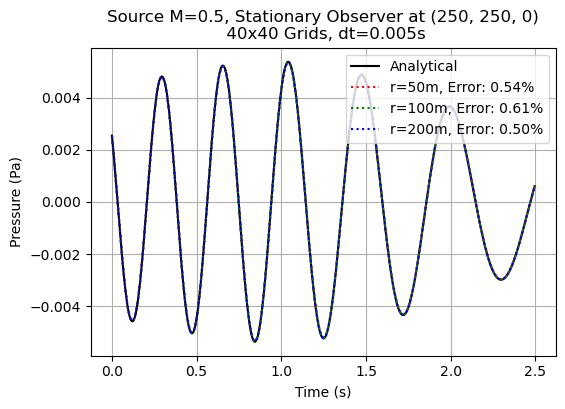

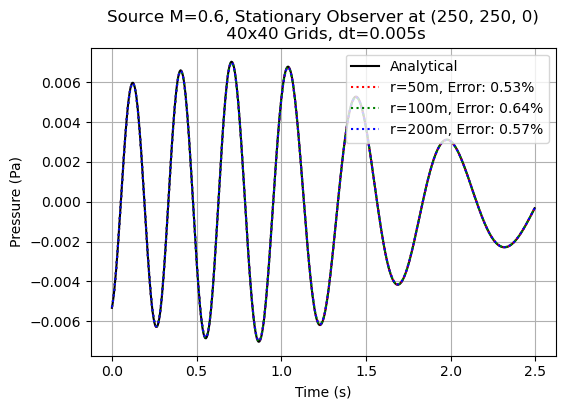

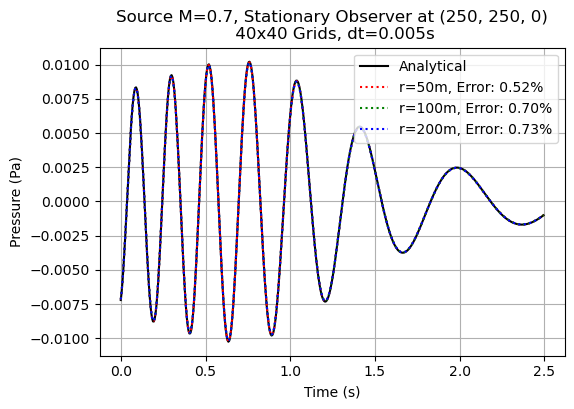

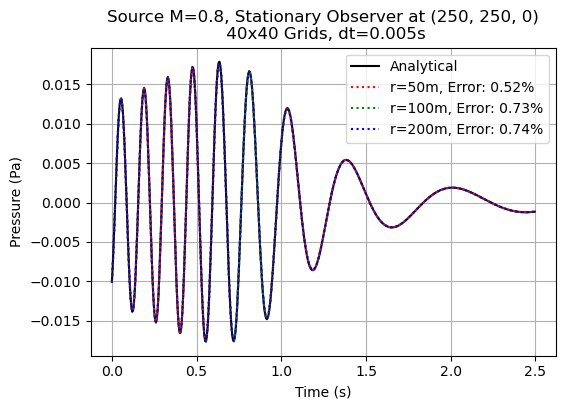

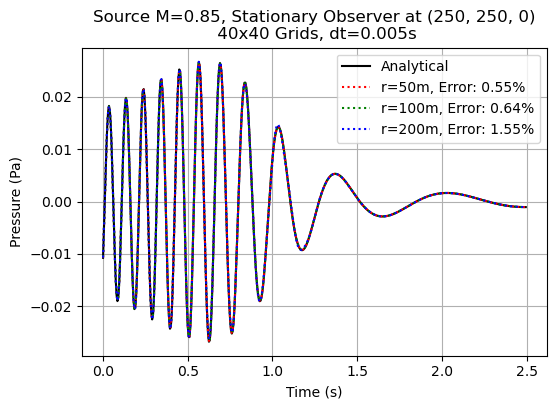

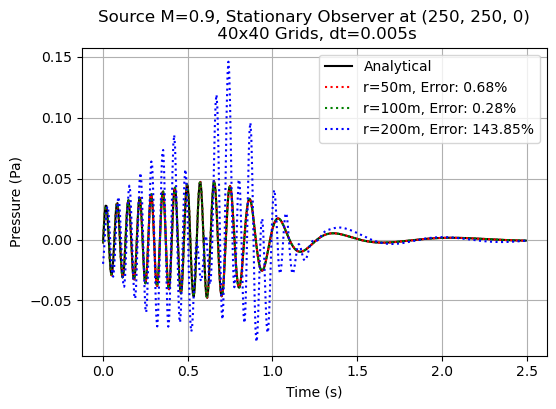

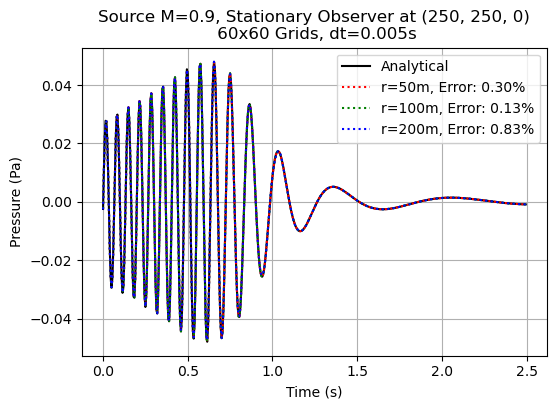

In [52]:
plot_mach(ana_M05, r050_M05,r100_M05, r200_M05, 'radius', 'Source M=0.5, Stationary Observer at (250, 250, 0)\n 40x40 Grids, dt=0.005s')
plot_mach(ana_M06, r050_M06,r100_M06, r200_M06, 'radius', 'Source M=0.6, Stationary Observer at (250, 250, 0)\n 40x40 Grids, dt=0.005s')
plot_mach(ana_M07, r050_M07,r100_M07, r200_M07, 'radius', 'Source M=0.7, Stationary Observer at (250, 250, 0)\n 40x40 Grids, dt=0.005s')
plot_mach(ana_M08, r050_M08,r100_M08, r200_M08, 'radius', 'Source M=0.8, Stationary Observer at (250, 250, 0)\n 40x40 Grids, dt=0.005s')
plot_mach(ana_M085, r050_M085,r100_M085, r200_M085, 'radius', 'Source M=0.85, Stationary Observer at (250, 250, 0)\n 40x40 Grids, dt=0.005s')
plot_mach(ana_M09, r050_M09,r100_M09, r200_M09, 'radius', 'Source M=0.9, Stationary Observer at (250, 250, 0)\n 40x40 Grids, dt=0.005s')
plot_mach(ana_M09, r050_M09f,r100_M09f, r200_M09f, 'radius', 'Source M=0.9, Stationary Observer at (250, 250, 0)\n 60x60 Grids, dt=0.005s')

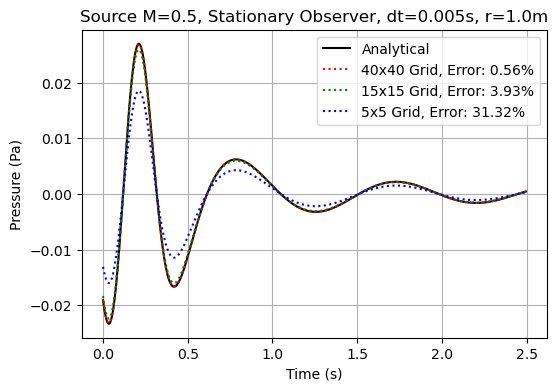

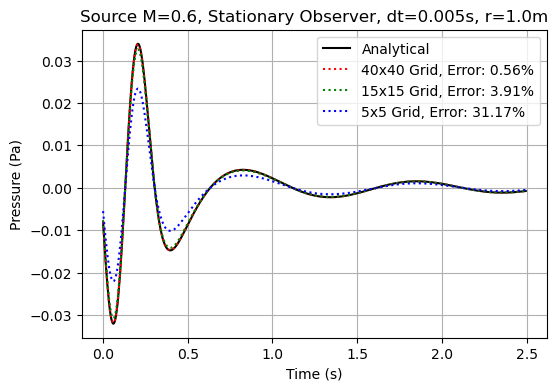

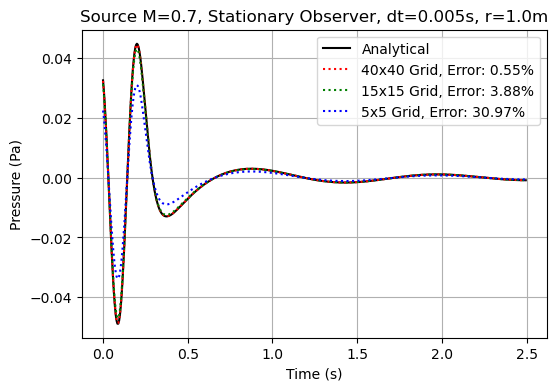

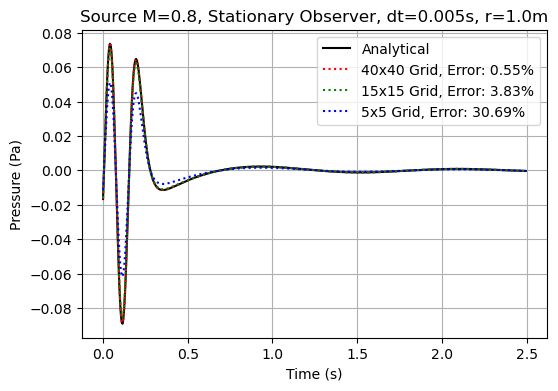

In [53]:
plot_mach(ana_05, fine_fine_05, med_fine_05, coarse_fine_05, 'grid', 'Source M=0.5, Stationary Observer, dt=0.005s, r=1.0m')
plot_mach(ana_06, fine_fine_06, med_fine_06, coarse_fine_06, 'grid', 'Source M=0.6, Stationary Observer, dt=0.005s, r=1.0m')
plot_mach(ana_07, fine_fine_07, med_fine_07, coarse_fine_07, 'grid', 'Source M=0.7, Stationary Observer, dt=0.005s, r=1.0m')
plot_mach(ana_08, fine_fine_08, med_fine_08, coarse_fine_08, 'grid', 'Source M=0.8, Stationary Observer, dt=0.005s, r=1.0m')

In [ ]:
plot_mach(ana_05, fine_fine_05, fine_med_05, fine_coarse_05, 'time', 'Source M=0.5, Stationary Observer, 40x40 Grid, r=1.0m')
plot_mach(ana_06, fine_fine_06, fine_med_06, fine_coarse_06, 'time', 'Source M=0.6, Stationary Observer, 40x40 Grid, r=1.0m')
plot_mach(ana_07, fine_fine_07, fine_med_07, fine_coarse_07, 'time', 'Source M=0.7, Stationary Observer, 40x40 Grid, r=1.0m')
plot_mach(ana_08, fine_fine_08, fine_med_08, fine_coarse_08, 'time', 'Source M=0.8, Stationary Observer, 40x40 Grid, r=1.0m')

In [ ]:
plot_mono(ss_fine_fine, ss_med_fine, ss_coarse_fine, 'grid', "Stationary Source, Stationary Observer, dt=0.005s")
plot_mono(ss_fine_fine, ss_fine_med, ss_fine_coarse, 'time', "Stationary Source and Observer, 40x40 Grid")

plot_mono(ts_fine_fine, ts_med_fine, ts_coarse_fine, 'grid', "Source Ux=150m/s, Stationary Observer, dt=0.005s")
plot_mono(ts_fine_fine, ts_fine_med, ts_fine_coarse, 'time', "Source Ux=150m/s, Stationary Observer, 40x40 Grid")

plot_mono(tt_fine_fine, tt_med_fine, tt_coarse_fine, 'grid', "Translating Source and Observer, Ux=150m/s, dt=0.005s")
plot_mono(tt_fine_fine, tt_fine_med, tt_fine_coarse, 'time', "Translating Source and Observer, Ux=150m/s, 40x40 Grid")

In [ ]:
plot_analytical(new_dipole, "Source Ux=150 m/s, Observer at (1500, 0, 0), r=500m \n Plane Wave Assumption")
plot_analytical(new_dual, "Source Ux=150 m/s, Observer at (1500,0,0), r=500m \n Dual Monopole Method")
plot_numerical(new_dual, new_dipole, "Source Ux=150 m/s, Observer at (1500, 0, 0), r=500m \n Dipole Plane Wave Assumption")

In [ ]:
plot_analytical(dual_near_valid, "Stationary Source, Observer at (50, 50, 0), r=1m")
plot_analytical(dual_near_invalid, "Source Ux=150 m/s, Observer at (50, 50, 0), r=1m")
plot_analytical(dual_far_valid, "Source Ux=150 m/s, Observer at (500, 500, 0), r=400m")
plot_analytical(dual_far_invalid, "Source Ux=150 m/s, Observer at (500, 500, 0), r=1m")

In [ ]:
plot_analytical(near_valid, "Stationary Source, Observer at (50, 50, 0), r=1m \n Zero Relative Mach Number Assumption")
plot_analytical(near_invalid, "Source Ux=150 m/s, Observer at (50, 50, 0), r=1m \n Zero Relative Mach Number Assumption")
plot_analytical(far_valid, "Source Ux=150 m/s, Observer at (500, 500, 0), r=400m \n Plane Wave Assumption")
plot_analytical(new_new_dipole, 'NEW')
plot_analytical(far_invalid, "Source Ux=150 m/s, Observer at (500, 500, 0), r=1m \n Plane Wave Assumption")

In [ ]:
plot_numerical(dual_near_valid, near_valid, "Stationary Source, Observer at (50, 50, 0), r=1m \n Dipole Zero Relative Mach Number Assumption")
plot_numerical(dual_near_invalid, near_invalid, "Source Ux=150 m/s, Observer at (50, 50, 0), r=1m \n Dipole Zero Relative Mach Number Assumption")
plot_numerical(dual_far_valid, far_valid, "Source Ux=150 m/s, Observer at (500, 500, 0), r=400m \n Dipole Plane Wave Assumption")

plot_numerical(dual_far_valid, new_new_dipole, "NEW STUFF YAY")

plot_numerical(dual_far_invalid, far_invalid, "Source Ux=150 m/s, Observer at (500, 500, 0), r=1m \n Dipole Plane Wave Assumption")

In [ ]:
# find directivity of the dual monopole code
def get_coord(distance, points):
    angles = np.linspace(0, 2 * np.pi, points)
    x = distance * np.cos(angles) #np.full(points, distance) 
    y = distance * np.sin(angles)
    z = np.zeros(points) #distance * np.cos(angles) #np.zeros(points)
    coord = np.column_stack((x, y, z))

    coord_string = []
    for row in coord:
        x, y, z = row
        coord_string.append(f"{x:.4f} {y:.4f} {z:.4f}\n")

    return coord_string, angles

def edit_config(path, coordinate):
    with open(path, 'r') as f:
        obs_loc = f.readlines()

    obs_loc[8] = coordinate

    with open(path, 'w') as f:
        f.writelines(obs_loc)

def directivity_run(filepath, distance, points, filename=None):
    coordinates, angles = get_coord(distance, points)
    max_pressures = []
    for i in range(points):
        edit_config(filepath, coordinates[i])
        os.system('../bin/dual_monopole_test > /dev/null 2>&1')
        try:
            data = np.loadtxt('FWH_pressure_new.dat')
            p_obs = data[:,1]
            steady_p = p_obs[int(len(p_obs) * 0.2):]
            p_rms = np.sqrt(np.mean(steady_p**2))
            max_p = p_rms * np.sqrt(2) #np.max(np.abs(p_obs))
            max_pressures.append(max_p)
        except FileNotFoundError:
            max_pressures.append(0.0)

    results = np.column_stack((angles, max_pressures))
    np.savetxt(filename, results, header="Theta(rad) Max_Pressure(Pa)")
    print(f'File {filename} saved!')

def directivity_plot(data, image, title=None):
    data = np.loadtxt(data, skiprows=1)

    theta = data[:,0]
    max_p = data[:,1]
    theta = np.append(theta, theta[0]) - (np.pi / 2)
    max_p = np.append(max_p, max_p[0])
    SPL = 20 * np.log10(np.abs(max_p) / 20e-6)
    SPL_normalised = SPL - np.max(SPL)

    # fig, (ax1, ax2) = plt.subplots(figsize=(10,6),nrows=1, ncols=2, subplot_kw={'projection': 'polar'})
    # fig.suptitle(title, weight='bold', y=0.95)

    # ax1.plot(theta, max_p * 1e5, color='red', label='FW-H Dual Monopole', marker=(4, 0, 0))
    # ax1.grid=True
    # ax1.set_title(f"Pressure ($x10^{-5}$ Pa)", va='bottom')

    # # ax2.plot(theta, SPL_normalised, color='red', label='SPL Directivity')
    # # ax2.set_rmin(-250)
    # # ax2.set_rmax(25)
    # # ax2.set_rticks([0, -50, -100, -150, -200, -250])
    # # ax2.grid=True
    # # ax2.set_title(f"Sound Pressure Level (dB)", va='bottom')
    # ax2.imshow(image)
    # ax2.axis('off')
    # ax2.set_title("Sound Pressure Level ")

    # using existing image
    fig = plt.figure(figsize=(10,6))
    fig.suptitle(title, weight='bold', y=0.95)
    ax1 = fig.add_subplot(1, 2, 1, projection='polar')
    ax1.plot(theta, max_p * 1e5, color='red', label='FW-H Dual Monopole', marker='D', markersize=4) # Swapped to standard diamond marker for cleaner rendering
    ax1.set_title(f"Pressure ($x10^{{-5}}$ Pa)", va='bottom')
    ax2 = fig.add_subplot(1, 2, 2)
    ax2.axis('off')
    ax2 = fig.add_axes([0.5, 0.15, 0.5, 0.665])
    ax2.imshow(image)
    ax2.axis('off')
    ax2.set_title("Sound Pressure Level (dB)")

    plt.show()

directivity_plot('directivity_stationary.dat', image_trans, f"Acoustic Directivity (R={distance})\n Stationary source and observer")
directivity_plot('directivity_moving.dat', image_stat, f"Acoustic Directivity (R={distance})\n Translating source Ux=10 m/s, stationary observer")

In [ ]:
filepath = 'config'
distance = 50.0
points = 72
image_stat = mpimg.imread("directivity_stat_fan.png")
image_trans = mpimg.imread("directivity_trans_fan.png")

In [ ]:
# directivity_run(filepath, distance, points, 'directivity_stationary.dat')

In [ ]:
# directivity_run(filepath, distance, points, 'directivity_moving.dat')

In [ ]:
directivity_plot('directivity_stationary.dat', image_trans, f"Acoustic Directivity (R={distance})\n Stationary source and observer")
directivity_plot('directivity_moving.dat', image_stat, f"Acoustic Directivity (R={distance})\n Translating source Ux=10 m/s, stationary observer")

In [4]:
class FWHCase:
    def __init__(self, name, filepath):
        self.name = name
        self.filepath = filepath
        self.data = self._load_data()
        
        # Added mach_str to the extracted attributes
        self.radius, self.mach, self.grid, self.mach_str = self._parse_metadata()

    def _parse_metadata(self):
        match = re.search(r"r(\d+)_M(\d+)([cmf])", self.name)
        if match:
            rad = int(match.group(1))
            
            raw_m_str = match.group(2) 

            mach = float(f"0.{raw_m_str[1:]}") 
            grid = match.group(3)
            
            return rad, mach, grid, raw_m_str
        return None, None, None, None

    def _load_data(self):
        df = pd.read_csv(self.filepath, sep=r'\s+', header=None, comment='#')
        if df.shape[1] == 3:
            df.columns = ['Time', 'P_obs', 'P_analytical']
        elif df.shape[1] == 2:
            df.columns = ['Time', 'P_obs']
        return df

    def L2_error(self, reference_data, col='P_obs'):
        ref_df = reference_data.data if hasattr(reference_data, 'data') else reference_data
        
        if len(self.data) != len(ref_df):
            t_fine = ref_df['Time'].values
            t_coarse = self.data['Time'].values
            p_coarse = self.data[col].values
            p_interp = np.interp(t_fine, t_coarse, p_coarse)
            abs_error = np.linalg.norm(ref_df[col].to_numpy() - p_interp)
        else:
            abs_error = np.linalg.norm(ref_df[col].to_numpy() - self.data[col].to_numpy())

        return abs_error / (np.linalg.norm(ref_df[col]) + 1e-15)

In [13]:
directory = Path("Data 260527/test_mach/")
results = {}

analytical_refs = {
    '05': ana_M05,
    '055': ana_M055,
    '06': ana_M06,
    '065': ana_M065,
    '07': ana_M07,
    '075': ana_M075,
    '08': ana_M08,
    '085': ana_M085,
    '09': ana_M09,
    '095': ana_M095,
}
for filepath in directory.glob("*.dat"):
    case = FWHCase(name=filepath.name, filepath=filepath)
    
    if case.mach is None:
        continue
        
    # Directly look up the exact string extracted from the filename
    ref_df = analytical_refs[case.mach_str]
    
    error = case.L2_error(ref_df, col='P_obs') * 100
    
    if case.radius not in results:
        results[case.radius] = {}
    if case.grid not in results[case.radius]:
        results[case.radius][case.grid] = []
        
    results[case.radius][case.grid].append((case.mach, error))

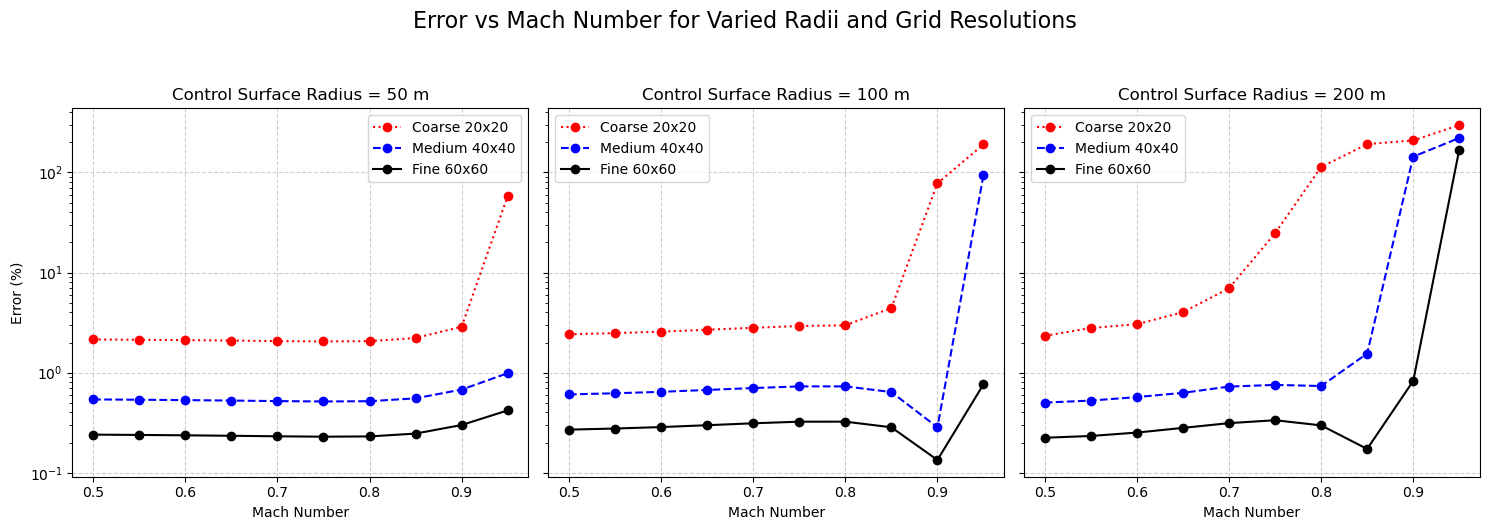

In [42]:
for rad in results:
    for grid in results[rad]:
        results[rad][grid].sort(key=lambda x: x[0])
radii_sorted = sorted(results.keys(), key=int)

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
fig.suptitle("Error vs Mach Number for Varied Radii and Grid Resolutions", fontsize=16, y=1.05)


for ax, rad in zip(axes, radii_sorted):
    for grid in ['c', 'm', 'f']:
        if grid in results[rad]:
            data = results[rad][grid]
            machs = [item[0] for item in data]
            errs = [item[1] for item in data]
            

            grid_styles = {'c': ':', 'm': '--', 'f': '-'}
            grid_colors = {'c': 'red', 'm': 'blue', 'f': 'black'}
            grid_labels = {'c': 'Coarse 20x20', 'm': 'Medium 40x40', 'f': 'Fine 60x60'}

            # ax.plot([], [], label=f'Base ')
            ax.plot(
                machs, errs,
                marker='o', 
                linestyle=grid_styles[grid], # Customized via attribute logic
                color=grid_colors[grid],     # Customized via 
                label=grid_labels[grid]
            )

            
    ax.set_title(f"Control Surface Radius = {rad} m")
    ax.set_xlabel("Mach Number")
    ax.set_yscale('log')
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.legend()

axes[0].set_ylabel("Error (%)")
# axes
plt.tight_layout()
plt.show()

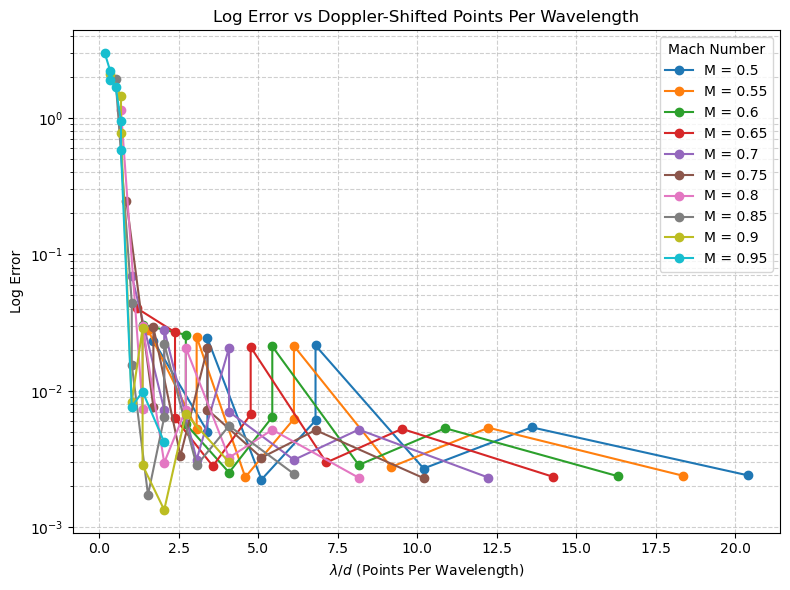

In [41]:
c = 340.0 
omega = 10.0
f_hz = omega / (2 * np.pi)   
lambda_source = c / f_hz

grid_points = {'c': 20, 'm': 40, 'f': 60} 

use_doppler = True

mach_results = {}

# --- Data Extraction ---
for filepath in directory.glob("*.dat"):
    case = FWHCase(name=filepath.name, filepath=filepath)
    if case.mach is None:
        continue
        
    ref_df = analytical_refs[case.mach_str]
    error = case.L2_error(ref_df, col='P_obs')
    
    N = grid_points[case.grid]
    d = (2 * np.pi * case.radius) / N
    
    if use_doppler:
        effective_lambda = c * (1 - case.mach) / f_hz 
    else:
        effective_lambda = lambda_source
        
    lambda_d = effective_lambda / d
    
    if case.mach_str not in mach_results:
        mach_results[case.mach_str] = []
        
    mach_results[case.mach_str].append((lambda_d, error))

fig, ax = plt.subplots(figsize=(8, 6))

for m_str in sorted(mach_results.keys()):
    data = mach_results[m_str]
    
    data.sort(key=lambda x: x[0]) 
    
    x_vals = [item[0] for item in data]
    y_vals = [item[1] for item in data]
    
    mach_float = float(f"0.{m_str[1:]}")
    
    ax.plot(x_vals, y_vals, marker='o', label=f"M = {mach_float}")


title_lambda = "Doppler-Shifted" if use_doppler else "Source"
ax.set_title(f"Log Error vs {title_lambda} Points Per Wavelength")
ax.set_xlabel(r"$\lambda / d$ (Points Per Wavelength)")
ax.set_ylabel("Log Error")

ax.set_yscale('log') 

ax.grid(True, which="both", linestyle='--', alpha=0.6)
ax.legend(title="Mach Number")

plt.tight_layout()
plt.show()

In [29]:
class FWHTimeCase:
    def __init__(self, name, filepath):
        self.name = name
        self.filepath = filepath
        self.data = self._load_data()
        self.mach, self.time_lbl, self.mach_str = self._parse_metadata()

    def _parse_metadata(self):
        """Extracts mach and time label from filenames like t_M09f.dat"""
        match = re.search(r"t_M(\d+)([cmf])", self.name)
        if match:
            raw_m_str = match.group(1) 
            mach = float(f"0.{raw_m_str[1:]}") 
            time_lbl = match.group(2)
            return mach, time_lbl, raw_m_str
        return None, None, None

    def _load_data(self):
        df = pd.read_csv(self.filepath, sep=r'\s+', header=None, comment='#')
        if df.shape[1] == 3:
            df.columns = ['Time', 'P_obs', 'P_analytical']
        elif df.shape[1] == 2:
            df.columns = ['Time', 'P_obs']
        return df

    def L2_error(self, reference_data, col='P_obs'):
        ref_df = reference_data.data if hasattr(reference_data, 'data') else reference_data
        
        if len(self.data) != len(ref_df):
            t_fine = ref_df['Time'].values
            t_coarse = self.data['Time'].values
            p_coarse = self.data[col].values
            p_interp = np.interp(t_fine, t_coarse, p_coarse)
            abs_error = np.linalg.norm(ref_df[col].to_numpy() - p_interp)
        else:
            abs_error = np.linalg.norm(ref_df[col].to_numpy() - self.data[col].to_numpy())

        return abs_error / (np.linalg.norm(ref_df[col]) + 1e-15)

directory = Path("Data 260527/test_mach/")
dt_values = {'c': 0.02, 'm': 0.01, 'f': 0.005}

plot1_results = {'c': [], 'm': [], 'f': []} 
plot2_results = {}

for filepath in directory.glob("t_M*.dat"): # Only process time-step files
    case = FWHTimeCase(name=filepath.name, filepath=filepath)
    
    if case.mach is None:
        continue
        
    ref_df = analytical_refs[case.mach_str]
    error = case.L2_error(ref_df, col='P_obs')
    
    plot1_results[case.time_lbl].append((case.mach, error))
    
    if case.mach_str not in plot2_results:
        plot2_results[case.mach_str] = []
    plot2_results[case.mach_str].append((case.time_lbl, error, case.mach))

for lbl in plot1_results:
    plot1_results[lbl].sort(key=lambda x: x[0])

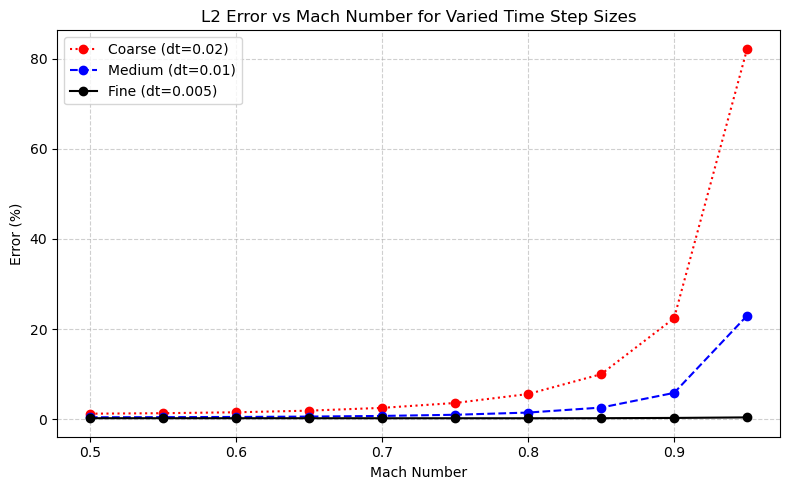

In [34]:
fig1, ax1 = plt.subplots(figsize=(8, 5))
time_labels = {'c': 'Coarse (dt=0.02)', 'm': 'Medium (dt=0.01)', 'f': 'Fine (dt=0.005)'}
time_styles = {'c': ':', 'm': '--', 'f': '-'}
time_colors = {'c': 'red', 'm': 'blue', 'f': 'black'}

for lbl in ['c', 'm', 'f']:
    if plot1_results[lbl]:
        data = plot1_results[lbl]
        machs = [item[0] for item in data]
        errs = [item[1] * 100 for item in data]
        
        ax1.plot(machs, errs, marker='o', 
                 linestyle=time_styles[lbl], 
                 color=time_colors[lbl], 
                 label=time_labels[lbl])

ax1.set_title("L2 Error vs Mach Number for Varied Time Step Sizes")
ax1.set_xlabel("Mach Number")
ax1.set_ylabel("Error (%)")
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend()
plt.tight_layout()
plt.show()

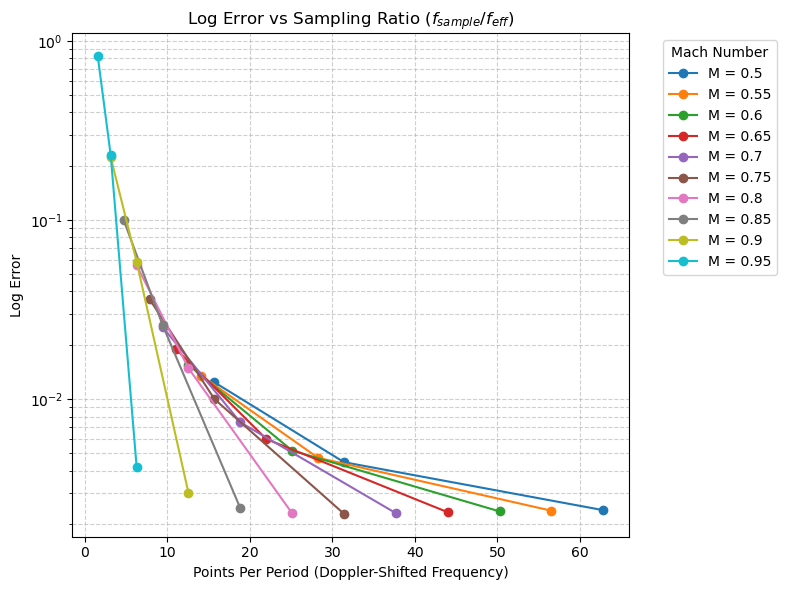

In [37]:
use_doppler = True

omega = 10.0
f_source = omega / (2 * np.pi)

fig2, ax2 = plt.subplots(figsize=(8, 6))

for m_str in sorted(plot2_results.keys()):
    data = plot2_results[m_str]
    mach_val = data[0][2] # Extract mach float from the first tuple
    
    plot_points = []
    
    for item in data:
        time_lbl, error, _ = item
        dt = dt_values[time_lbl]
        
        f_sample = 1.0 / dt
        
        if use_doppler:
            f_eff = f_source / (1 - mach_val) 
        else:
            f_eff = f_source
            
        sampling_ratio = f_sample / f_eff
        
        plot_points.append((sampling_ratio, error))
        
    # Sort by sampling ratio (x-axis)
    plot_points.sort(key=lambda x: x[0])
    
    x_vals = [p[0] for p in plot_points]
    y_vals = [p[1] for p in plot_points]
    
    mach_float = float(f"0.{m_str[1:]}")
    ax2.plot(x_vals, y_vals, marker='o', label=f"M = {mach_float}")

title_shift = "Doppler-Shifted " if use_doppler else "Source "
ax2.set_title(f"Log Error vs Sampling Ratio ($f_{{sample}} / f_{{eff}}$)")
ax2.set_xlabel(f"Points Per Period ({title_shift}Frequency)")
ax2.set_ylabel("Log Error")
ax2.set_yscale('log') 
ax2.grid(True, which="both", linestyle='--', alpha=0.6)
ax2.legend(title="Mach Number", bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()